# Evaluate surrogate-screened search

**Question:** How does the evaluate surrogate-screened search analysis change when the same authored ore is run at controlled throughput settings?

Level: 3. Prerequisites: Levels 1 and 2 of this topic and level 3 of learning. Reading time: 26 minutes.

## Objectives

Compare the screened and unscreened search evidence in the same committed benchmark row, then interpret how the objective weight changes recovery-energy trade-offs.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; `data/derived/benchmark.json` stores the evaluated optimizer variants for twelve authored cases, MIT project licence. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

A surrogate-management framework may order proposed evaluations, but OreFlow still evaluates candidates with its process engine. The autoencoder guard and Gaussian-process interval limit screen proposals; the search poll remains authoritative. The weight path reports the conditional trade-off between recovered metal and specific energy. This notebook compares measured evaluation counts and baked path records; it claims no new optimization algorithm.

## Comparison

Generalized pattern search and progressive barriers are established derivative-free methods (Torczon, 1997; Audet and Dennis, 2009). Surrogate management can guide expensive design evaluations (Booker et al., 1999). OreFlow's evidence is case-specific: screened and unscreened runs reach the same recorded optimum on this row, while the recorded evaluation counts reveal whether screening saved work. This is not a proof for every case or an economic optimum.

Load the benchmark's screened-versus-unscreened comparison and report what the engine actually evaluated.

In [2]:
# Load the benchmark's screened-versus-unscreened comparison and report what the engine actually
# evaluated.
repo = Path("../../../").resolve()
benchmark = json.loads((repo / "data/derived/benchmark.json").read_text(encoding="utf-8"))
row = benchmark["optimization"]["copper_porphyry_soft"]["nominal"]
comparison = pd.DataFrame(
    [
        {"search": "surrogate screened", "evaluations": row["evaluations"]},
        {"search": "unscreened", "evaluations": row["evaluations_without_screen"]},
    ]
)
print("same optimum:", row["same_optimum_without_screen"])
print("screen proposals:", row["proposed"], "| improved incumbents:", row["improved"])
print("engine evaluations saved:", row["evaluations_without_screen"] - row["evaluations"])
display(comparison)


same optimum: True
screen proposals: 72 | improved incumbents: 18
engine evaluations saved: -43


,search,evaluations
0,surrogate screened,309
1,unscreened,266


Plot the recorded weight path. Lower metal weight changes the objective; it does not alter the ore or plant model.

,weight,status,recovered_tph,energy_kwh_t
0,0.75,optimal,5.013899,10.213139
1,0.50,optimal,4.198802,7.349207
2,0.25,optimal,3.969572,7.102007


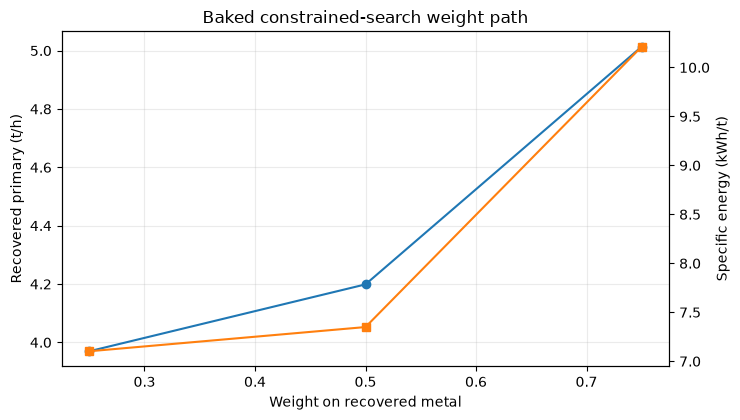

In [3]:
# Plot the recorded weight path.
path = pd.DataFrame(row["path"])
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(path["weight"], path["recovered_tph"], marker="o", label="recovered primary")
ax.set(
    xlabel="Weight on recovered metal",
    ylabel="Recovered primary (t/h)",
    title="Baked constrained-search weight path",
)
ax.grid(True, alpha=0.25)
ax2 = ax.twinx()
ax2.plot(
    path["weight"], path["energy_kwh_t"], marker="s", color="tab:orange", label="specific energy"
)
ax2.set_ylabel("Specific energy (kWh/t)")
fig.tight_layout()
display(path)


Read evaluation saving beside the screened surrogate's absolute recovery error; neither quantity measures plant performance.

Figure 12 in level 3 04 optimization summarizes solved OreFlow circuits at the stated settings. The connecting line guides comparison only; it is not a fitted response law or confidence band. Check the axes against the contract and paired outputs for this operating question.

In [4]:
# Read evaluation saving beside the screened surrogate's absolute recovery error; neither quantity
# measures plant performance.
print("screened evaluations:", row["evaluations"])
print("unscreened evaluations:", row["evaluations_without_screen"])
print("surrogate absolute error (percentage points):", round(row["surrogate_abs_error_pp"], 4))
print("same optimum:", row["same_optimum_without_screen"])
print("limits: authored simulator cases only; no field calibration or economic objective")


screened evaluations: 309
unscreened evaluations: 266
surrogate absolute error (percentage points): 0.4126
same optimum: True
limits: authored simulator cases only; no field calibration or economic objective


For the level 3 04 optimization case, only fresh-feed rate changes at 0.8 times nominal throughput. This level 3 04 optimization comparison at 0.8 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [5]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_1 = 0.8
point_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_1)
response_1 = simulate(case.ore, case.plant, point_1)
print('throughput (t/h):', round(point_1.throughput_tph, 2))
print('recovery (%):', round(response_1.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_1.metrics['p80_um'], 2))

throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


For the level 3 04 optimization case, only fresh-feed rate changes at 0.9 times nominal throughput. This level 3 04 optimization comparison at 0.9 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [6]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_2 = 0.9
point_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_2)
response_2 = simulate(case.ore, case.plant, point_2)
print('throughput (t/h):', round(point_2.throughput_tph, 2))
print('recovery (%):', round(response_2.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_2.metrics['p80_um'], 2))

throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


For the level 3 04 optimization case, only fresh-feed rate changes at 1.0 times nominal throughput. This level 3 04 optimization comparison at 1.0 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [7]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_3 = 1.0
point_3 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_3)
response_3 = simulate(case.ore, case.plant, point_3)
print('throughput (t/h):', round(point_3.throughput_tph, 2))
print('recovery (%):', round(response_3.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_3.metrics['p80_um'], 2))

throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


For the level 3 04 optimization case, only fresh-feed rate changes at 1.1 times nominal throughput. This level 3 04 optimization comparison at 1.1 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [8]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_4 = 1.1
point_4 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_4)
response_4 = simulate(case.ore, case.plant, point_4)
print('throughput (t/h):', round(point_4.throughput_tph, 2))
print('recovery (%):', round(response_4.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_4.metrics['p80_um'], 2))

throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


For the level 3 04 optimization case, only fresh-feed rate changes at 1.2 times nominal throughput. This level 3 04 optimization comparison at 1.2 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [9]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_5 = 1.2
point_5 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_5)
response_5 = simulate(case.ore, case.plant, point_5)
print('throughput (t/h):', round(point_5.throughput_tph, 2))
print('recovery (%):', round(response_5.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_5.metrics['p80_um'], 2))

throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


For level 3 04 optimization, the panels use identical settings and 5 solved model points rather than plant observations. At level 3, the 04 optimization trend is a local response from one authored case and can change near power or grade constraints; it is not a causal plant estimate.

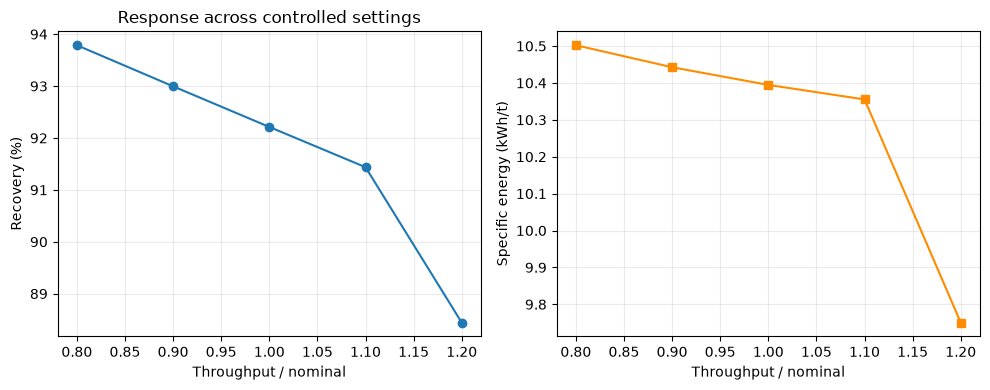

In [10]:
# Compare recovery and specific energy from the executed circuit runs.
import matplotlib.pyplot as plt
factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_1, response_2, response_3, response_4, response_5]
recovery = [run.metrics['recovery_pct'] for run in runs]
energy = [run.metrics['specific_energy_total_kwh_t'] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, recovery, marker='o')
axes[0].set(xlabel='Throughput / nominal', ylabel='Recovery (%)', title='Response across controlled settings')
axes[1].plot(factors, energy, marker='s', color='darkorange')
axes[1].set(xlabel='Throughput / nominal', ylabel='Specific energy (kWh/t)')
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()

In the level 3 04 optimization analysis, read this size response alongside the recovery and energy panels rather than as a substitute. At level 3, a constant grind target in this 04 optimization case can keep P80 nearly unchanged while power limits, recycle and residence alter other outputs. For 04 optimization at level 3, retain model flags and the mass-balance audit with the result.

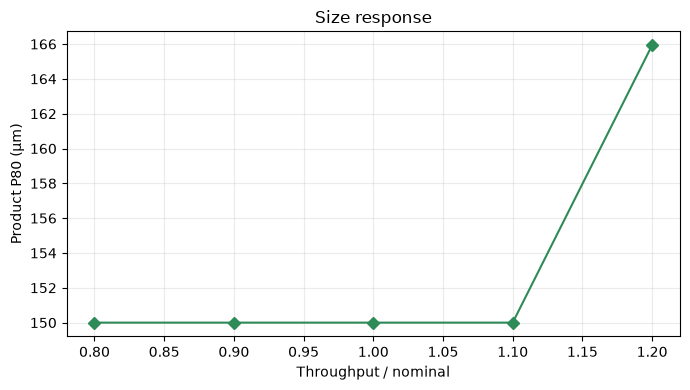

In [11]:
# Show product size separately because it is measured in micrometres, not energy or recovery.
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [run.metrics['p80_um'] for run in runs]
ax.plot(factors, sizes, marker='D', color='seagreen')
ax.set(xlabel='Throughput / nominal', ylabel='Product P80 (µm)', title='Size response')
ax.grid(True, alpha=0.25)
fig.tight_layout()

At level 3 in 04 optimization, interpretation 1 is that an optimization result depends on the objective, feasible region, initial point and stopping condition. At level 3 in 04 optimization, interpretation 2 is that oreFlow's search evaluates a mineral-processing circuit and uses a progressive barrier to move toward feasibility. At level 3 in 04 optimization, interpretation 3 is that its decision variables are not interchangeable because grind size, collector dose and gas velocity affect different constraints. At level 3 in 04 optimization, interpretation 4 is that a scalar score can conceal a trade-off, so inspect recovered metal, specific energy, concentrate grade, water and constraint slack together. At level 3 in 04 optimization, interpretation 5 is that the committed benchmark compares screened and unscreened runs on paired authored cases and counts exact engine evaluations. At level 3 in 04 optimization, interpretation 6 is that a surrogate may prioritize candidates, but only the process engine decides the physical outputs. At level 3 in 04 optimization, interpretation 7 is that re-evaluate each reported optimum with that engine, preserve refused and infeasible runs, and report the stopping reason. At level 3 in 04 optimization, interpretation 8 is that the comparison supports method inspection only; a plant decision still requires an independently calibrated campaign and an operations-approved cost model. At level 3 in 04 optimization, interpretation 9 is that a deployment study would need plant-specific bounds, validated assay and sensor data, a cost model approved by operations, and a holdout campaign. At level 3 in 04 optimization, interpretation 10 is that sensitivity to objective weights should be shown as a Pareto trade-off rather than collapsed to one universally best setting.

Execute one fresh unscreened reference search with the same case and contract. Its process evaluations are more expensive than reading the saved multi-case record, but they demonstrate the method directly.

In [12]:
# Run the unscreened product search on the authored case.
from pipeline.io.contract import build_contract
from pipeline.methods.optimization import optimize
search_reference = optimize(case, case.nominal, build_contract(), weight=0.5, path=False)
print('search method:', search_reference['method'])
print('search evaluations:', search_reference['evaluations'])

search method: gps-progressive-barrier
search evaluations: 258


## Results

**Answer:** In this level 3 04 optimization lesson, the executed circuit reports recovery of 93.788 percent at the first controlled throughput setting for Evaluate surrogate-screened search.

The evaluation-count comparison measures computational work on one baked search. The weight path reveals the recovery-energy exchange under the engine's constraints. Neither the screened estimate error nor a matching endpoint says how a real plant would respond.

## Summary

You compared surrogate-assisted evaluation ordering with an engine-only search and inspected a baked objective path. The claim is narrow: methods are compared on OreFlow's authored cases, with no plant-validation claim.

## References

- https://doi.org/10.1137/S1052623493250780
- https://doi.org/10.1137/070692662
- https://doi.org/10.1007/BF01197708
- https://doi.org/10.1017/CBO9780511790423